## 1. Importing Required Libraries

In this project, various Python libraries are used for data
manipulation, visualization, preprocessing, machine learning
model development, and evaluation.

Pandas and NumPy are used for data handling and numerical
operations.

Matplotlib and Seaborn are used for data visualization.

Scikit-learn is used for preprocessing, implementing regression
algorithms, evaluating model performance, and hyperparameter tuning.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR

# Model evaluation
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Cross validation and hyperparameter tuning
from sklearn.model_selection import (
    cross_val_score,
    GridSearchCV,
    KFold
)

# Feature importance
from sklearn.inspection import permutation_importance

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

The dataset contains information about different automobiles
available in the American market.

It includes variables related to car specifications, engine
characteristics, fuel systems, dimensions, and selling prices.

The target variable is 'price', which represents the price of
the automobile.

We will load the CSV file using Pandas.

In [2]:
# Load dataset
df = pd.read_csv("CarPrice_Assignment.csv")

# Display first five rows
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
print("Dataset Shape:", df.shape)

print("Number of Rows:", df.shape[0])

print("Number of Columns:", df.shape[1])

Dataset Shape: (205, 26)
Number of Rows: 205
Number of Columns: 26


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    int64  
 17  fuelsyst

In [5]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [6]:
print("Columns in the dataset:")

print(df.columns.tolist())

Columns in the dataset:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']


## 3. Data Understanding

In this section, we examine the structure and quality of the
dataset.

We check for:
1. Missing values.
2. Duplicate records.
3. Data types.
4. Unique values.
5. Target variable distribution.

This helps us understand the dataset before performing
preprocessing and model development.

In [7]:
# Check missing values in each column

df.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

In [8]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [10]:
for col in df.columns:
    print(col, ":", df[col].nunique())

car_ID : 205
symboling : 6
CarName : 147
fueltype : 2
aspiration : 2
doornumber : 2
carbody : 5
drivewheel : 3
enginelocation : 2
wheelbase : 53
carlength : 75
carwidth : 44
carheight : 49
curbweight : 171
enginetype : 7
cylindernumber : 7
enginesize : 44
fuelsystem : 8
boreratio : 38
stroke : 37
compressionratio : 32
horsepower : 59
peakrpm : 23
citympg : 29
highwaympg : 30
price : 189


In [11]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['car_ID', 'symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Categorical Columns:
['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


### Observation

The dataset contains 205 observations and 26 columns.

The dataset includes both numerical and categorical variables.

There are no missing values in the original dataset.

The target variable for this project is 'price'.

The dataset is suitable for developing regression models
after appropriate preprocessing.

## 4. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the
distribution of variables and identify relationships between
different automobile characteristics and their prices.

Various graphical techniques are used to identify patterns,
trends, and possible outliers.

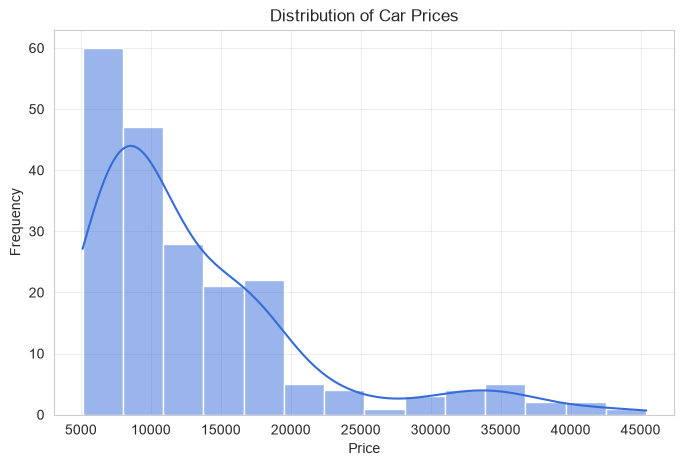

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

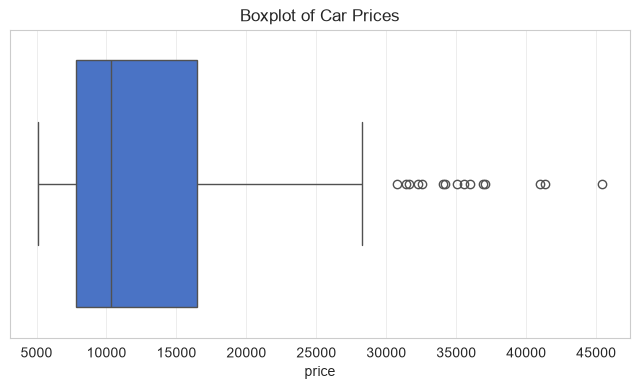

In [13]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['price'])

plt.title("Boxplot of Car Prices")

plt.show()

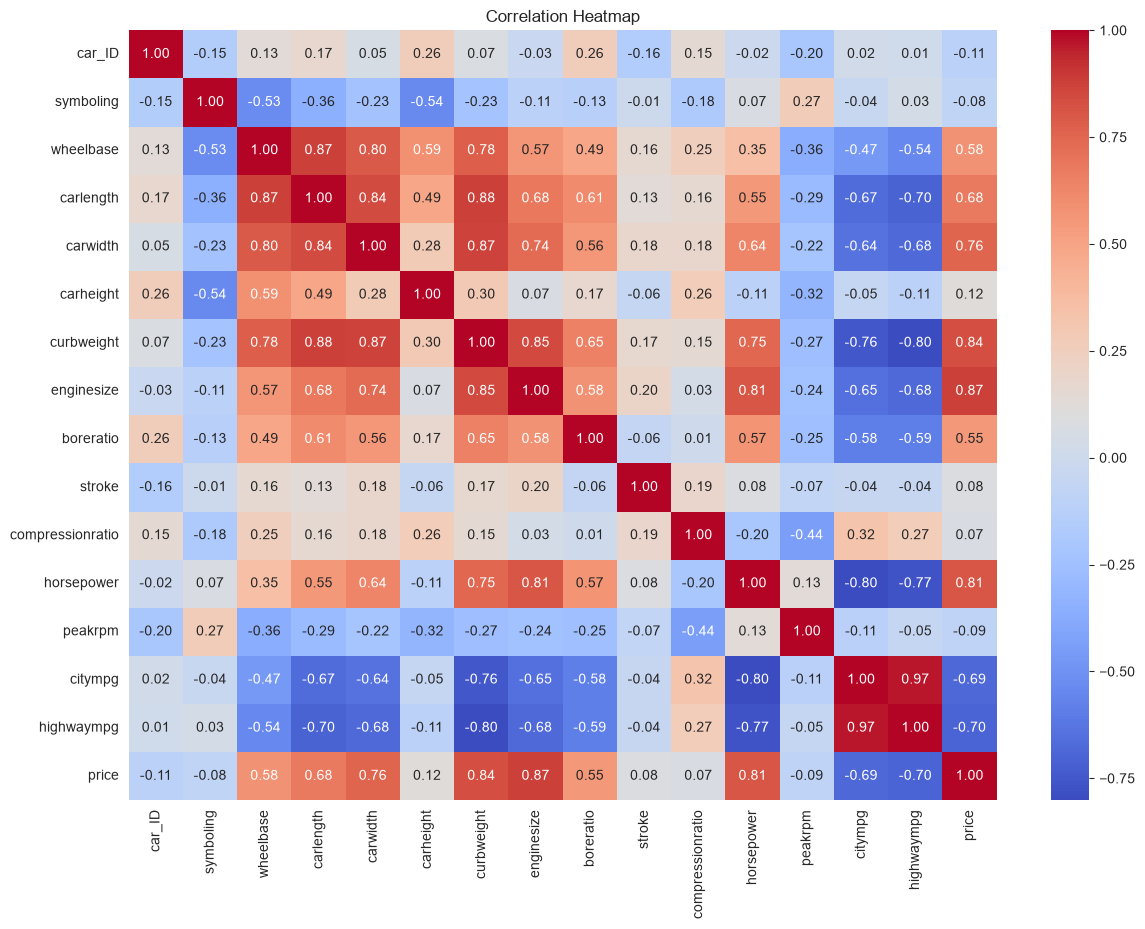

In [14]:
plt.figure(figsize=(14,10))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

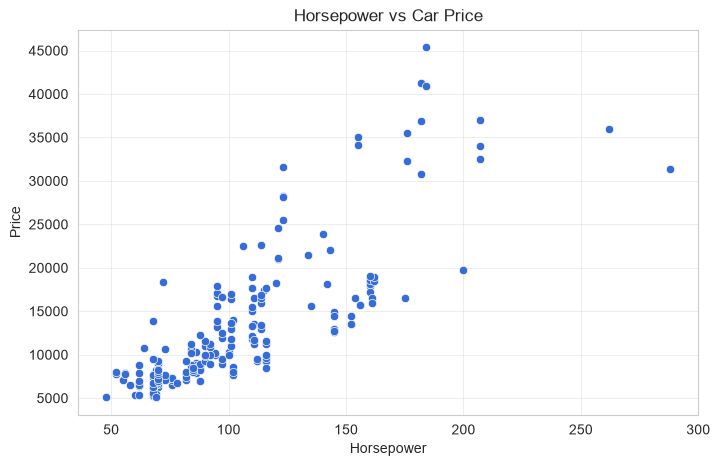

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='horsepower',
    y='price',
    data=df
)

plt.title("Horsepower vs Car Price")

plt.xlabel("Horsepower")
plt.ylabel("Price")

plt.show()

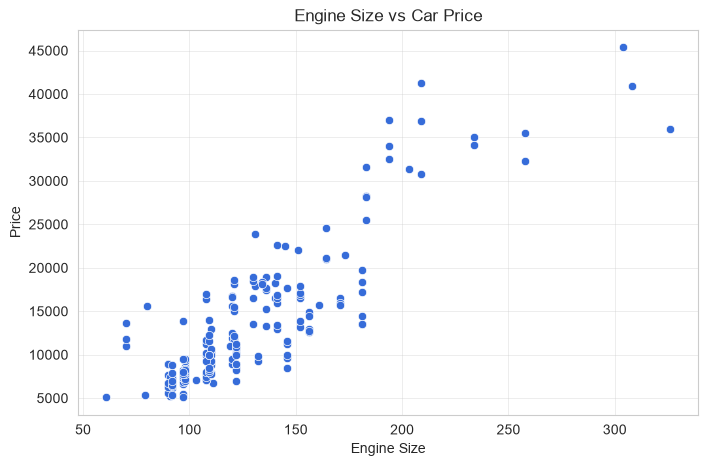

In [16]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='enginesize',
    y='price',
    data=df
)

plt.title("Engine Size vs Car Price")

plt.xlabel("Engine Size")
plt.ylabel("Price")

plt.show()

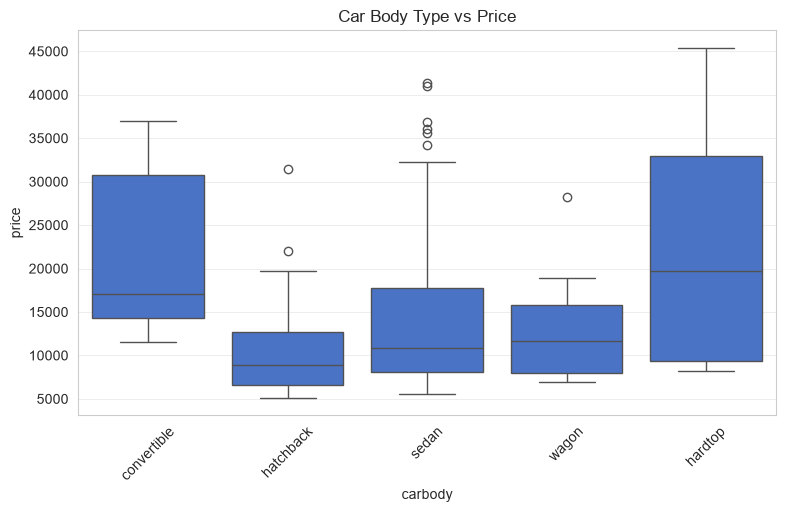

In [17]:
plt.figure(figsize=(9,5))

sns.boxplot(
    x='carbody',
    y='price',
    data=df
)

plt.title("Car Body Type vs Price")

plt.xticks(rotation=45)

plt.show()

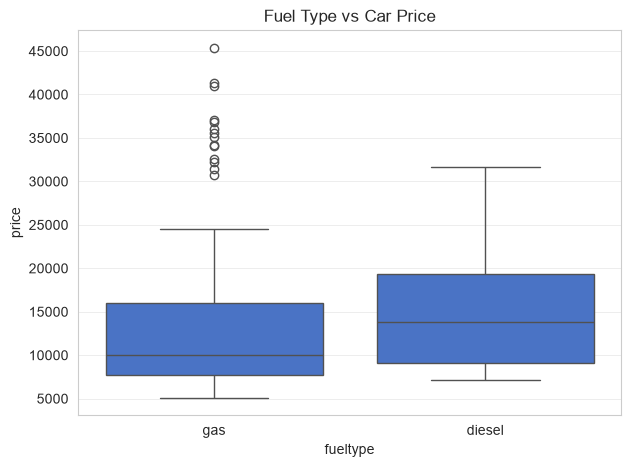

In [18]:
plt.figure(figsize=(7,5))

sns.boxplot(
    x='fueltype',
    y='price',
    data=df
)

plt.title("Fuel Type vs Car Price")

plt.show()

### EDA Observations

1. Car prices show variation across different automobile
   categories.

2. Engine size and horsepower may have a positive relationship
   with car prices.

3. Different car body types have different price distributions.

4. Potential outliers are observed in the price distribution.

5. Correlation analysis provides an initial understanding
   of the relationships between numerical variables.

These observations help us understand the factors that may
influence car prices.

## 5. Data Preprocessing

Data preprocessing is performed to prepare the dataset for
machine learning algorithms.

The following preprocessing steps are carried out:

1. Removing unnecessary columns.
2. Extracting automobile manufacturers from car names.
3. Handling duplicate records.
4. Identifying numerical and categorical variables.
5. Handling missing values using appropriate imputation methods.
6. Encoding categorical variables.
7. Scaling numerical variables.

Categorical variables are converted into numerical representations
using One-Hot Encoding.

Numerical variables are standardized using StandardScaler.

A preprocessing pipeline is used to ensure consistent
preprocessing during model training and testing.

In [19]:
# Create a copy of the dataset

data = df.copy()

# Remove car_ID

data.drop('car_ID', axis=1, inplace=True)

print("Updated Shape:", data.shape)

Updated Shape: (205, 25)


In [20]:
# Extract manufacturer name

data['manufacturer'] = data['CarName'].str.split().str[0]

# Remove original CarName column

data.drop('CarName', axis=1, inplace=True)

data[['manufacturer']].head()

,manufacturer
0,alfa-romero
1,alfa-romero
2,alfa-romero
3,audi
4,audi


In [21]:
# Standardize manufacturer names

data['manufacturer'] = data['manufacturer'].str.lower()

manufacturer_mapping = {
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
}

data['manufacturer'] = data['manufacturer'].replace(
    manufacturer_mapping
)

print(data['manufacturer'].unique())

['alfa-romero' 'audi' 'bmw' 'chevrolet' 'dodge' 'honda' 'isuzu' 'jaguar'
 'mazda' 'buick' 'mercury' 'mitsubishi' 'nissan' 'peugeot' 'plymouth'
 'porsche' 'renault' 'saab' 'subaru' 'toyota' 'volkswagen' 'volvo']


In [22]:
print("Duplicate records:", data.duplicated().sum())

data.drop_duplicates(inplace=True)

Duplicate records: 0


### Separating Independent and Dependent Variables

The target variable is 'price'.

All remaining columns are considered independent variables
used to predict the automobile price.

X represents the independent variables.

y represents the dependent variable.

In [23]:
# Independent variables

X = data.drop('price', axis=1)

# Dependent variable

y = data['price']

print("Independent Variables Shape:", X.shape)

print("Target Variable Shape:", y.shape)

Independent Variables Shape: (205, 24)
Target Variable Shape: (205,)


In [24]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']

Categorical Features:
['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'manufacturer']


### Creating Preprocessing Pipeline

A preprocessing pipeline is created to handle numerical and
categorical variables separately.

For numerical variables:
- Missing values are handled using median imputation.
- StandardScaler is applied for feature scaling.

For categorical variables:
- Missing values are handled using the most frequent value.
- One-Hot Encoding is applied to convert categorical variables
  into numerical features.

Using a pipeline ensures that preprocessing is performed
consistently without data leakage from the test dataset.

In [25]:
# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


# Combine preprocessing steps

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 6. Splitting the Dataset into Training and Testing Sets

The dataset is divided into training and testing sets.

80% of the data is used for training the machine learning
models, while the remaining 20% is used for testing.

The training dataset helps the models learn the relationship
between automobile characteristics and prices.

The testing dataset is used to evaluate how well the models
perform on unseen observations.

A random state is specified to ensure reproducibility.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)

print("Testing Target Shape:", y_test.shape)

Training Data Shape: (164, 24)
Testing Data Shape: (41, 24)
Training Target Shape: (164,)
Testing Target Shape: (41,)


## 7. Model Implementation

In this section, five regression algorithms are implemented
to predict automobile prices.

The selected algorithms are:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. Support Vector Regressor

Each model is combined with the preprocessing pipeline.

The models are trained using the training dataset and their
predictions are generated using the testing dataset.

This allows us to compare the performance of different
regression techniques.

In [27]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    ),

    'Support Vector Regressor': SVR()
}

In [28]:
trained_models = {}

for name, model in models.items():

    # Create pipeline

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train model

    pipeline.fit(X_train, y_train)

    # Store trained model

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!
Support Vector Regressor trained successfully!


In [29]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name, "predictions generated successfully!")

Linear Regression predictions generated successfully!
Decision Tree predictions generated successfully!
Random Forest predictions generated successfully!
Gradient Boosting predictions generated successfully!
Support Vector Regressor predictions generated successfully!


## 8. Model Evaluation

The performance of the five regression models is evaluated
using three statistical metrics.

1. R-squared (R²):
   Measures how much variation in the target variable is
   explained by the model.
   Higher values indicate better performance.

2. Mean Squared Error (MSE):
   Measures the average squared difference between actual
   and predicted values.
   Lower values indicate better performance.

3. Mean Absolute Error (MAE):
   Measures the average absolute difference between actual
   and predicted values.
   Lower values indicate better performance.

These metrics are used to compare the predictive performance
of all five regression algorithms.

In [30]:
results = []

for name, y_pred in predictions.items():

    r2 = r2_score(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        'Model': name,
        'R2 Score': r2,
        'MSE': mse,
        'MAE': mae
    })


results_df = pd.DataFrame(results)

results_df

,Model,R2 Score,MSE,MAE
0,Linear Regression,0.901085,7.808716e+06,1807.703987
1,Decision Tree,0.906301,7.396941e+06,1785.776415
2,Random Forest,0.956721,3.416608e+06,1309.436415
3,Gradient Boosting,0.927953,5.687654e+06,1671.835344
4,Support Vector Regressor,-0.099791,8.682195e+07,5695.303050


In [31]:
results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

results_df

,Model,R2 Score,MSE,MAE
2,Random Forest,0.956721,3.416608e+06,1309.436415
3,Gradient Boosting,0.927953,5.687654e+06,1671.835344
1,Decision Tree,0.906301,7.396941e+06,1785.776415
0,Linear Regression,0.901085,7.808716e+06,1807.703987
4,Support Vector Regressor,-0.099791,8.682195e+07,5695.303050


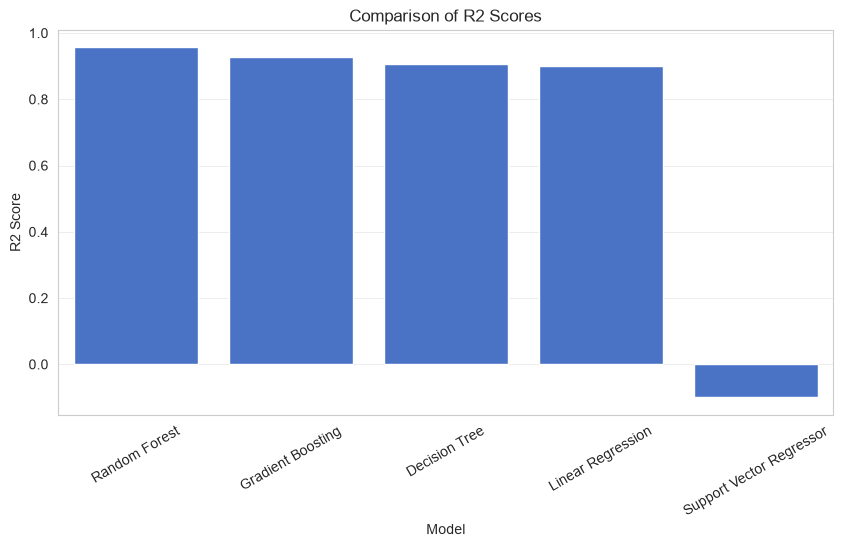

In [32]:
plt.figure(figsize=(10,5))

sns.barplot(
    x='Model',
    y='R2 Score',
    data=results_df
)

plt.title("Comparison of R2 Scores")

plt.xticks(rotation=30)

plt.show()

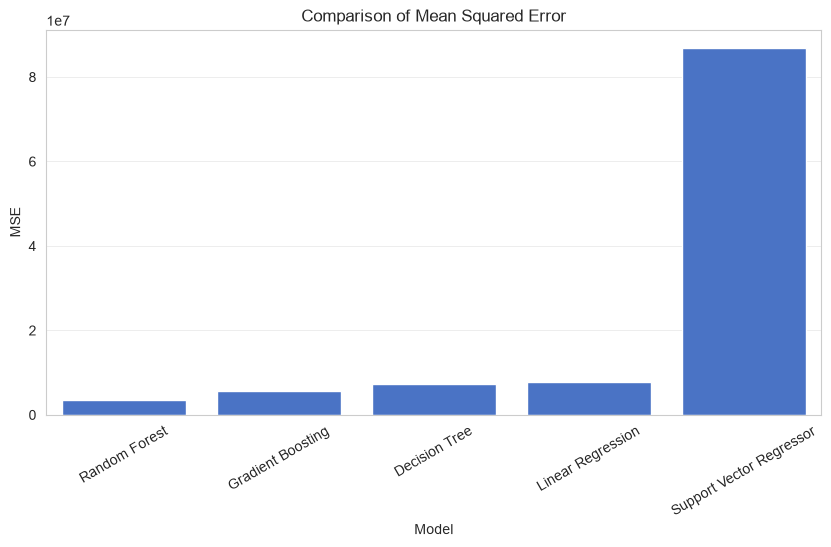

In [33]:
plt.figure(figsize=(10,5))

sns.barplot(
    x='Model',
    y='MSE',
    data=results_df
)

plt.title("Comparison of Mean Squared Error")

plt.xticks(rotation=30)

plt.show()

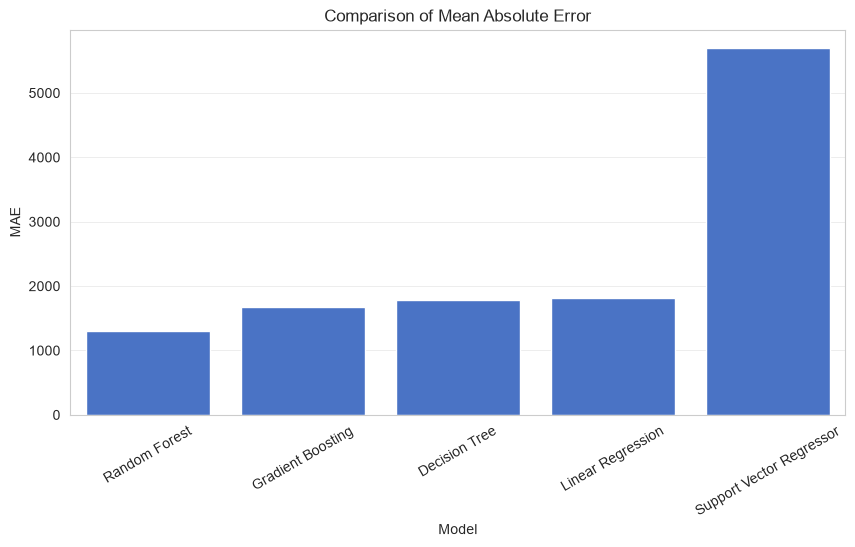

In [34]:
plt.figure(figsize=(10,5))

sns.barplot(
    x='Model',
    y='MAE',
    data=results_df
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.show()

In [35]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

print("Best R2 Score:", results_df.iloc[0]['R2 Score'])

print("Best MSE:", results_df.iloc[0]['MSE'])

print("Best MAE:", results_df.iloc[0]['MAE'])

Best Performing Model: Random Forest
Best R2 Score: 0.9567211359310729
Best MSE: 3416607.5487052524
Best MAE: 1309.4364146341463


### Model Evaluation Interpretation

The performance of all five regression algorithms is compared
using R-squared, Mean Squared Error, and Mean Absolute Error.

The model with the highest R-squared value and comparatively
lower error values is considered the best-performing model.

The selected model will be used for further analysis and
hyperparameter tuning.

## 9. Feature Importance Analysis

Feature importance analysis is performed to identify the
independent variables that contribute most to predicting
automobile prices.

Permutation Importance is used to evaluate the importance
of each feature.

It measures how much the model performance decreases when
the values of an individual feature are randomly shuffled.

Features causing a larger decrease in model performance
are considered more important.

This analysis helps management understand the major factors
influencing automobile pricing.

In [36]:
# Calculate permutation importance

perm_importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring='r2'
)

# Create feature importance dataframe

feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_importance.importances_mean
})

# Sort by importance

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
14,enginesize,0.756122
11,curbweight,0.141002
22,highwaympg,0.008934
19,horsepower,0.005931
9,carwidth,0.003602
21,citympg,0.003349
23,manufacturer,0.002419
18,compressionratio,0.002412
16,boreratio,0.002157
8,carlength,0.002101


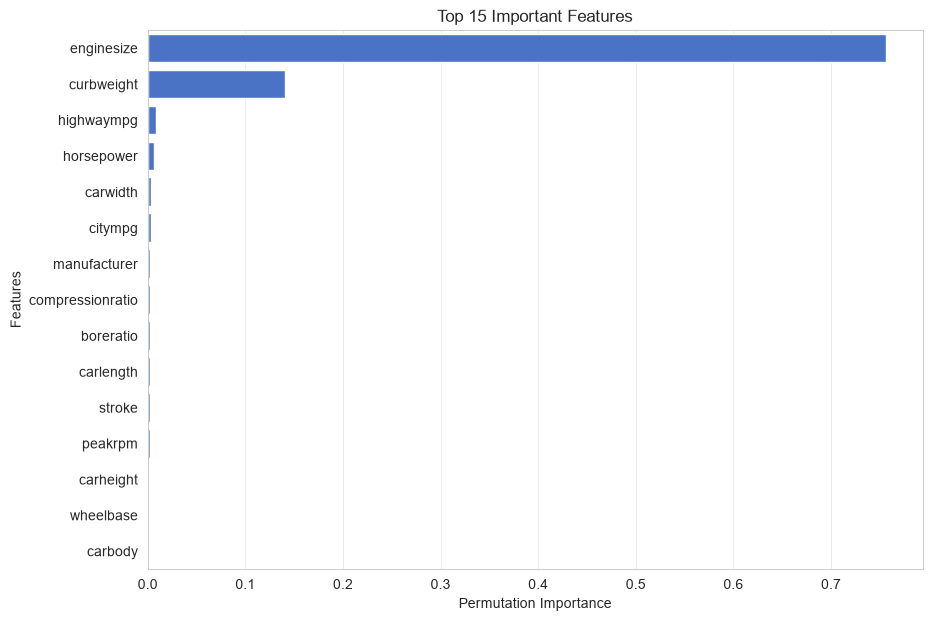

In [37]:
plt.figure(figsize=(10,7))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(15)
)

plt.title("Top 15 Important Features")

plt.xlabel("Permutation Importance")

plt.ylabel("Features")

plt.show()

In [38]:
print("Top 5 Important Features:")

print(feature_importance.head(5))

Top 5 Important Features:
       Feature  Importance
14  enginesize    0.756122
11  curbweight    0.141002
22  highwaympg    0.008934
19  horsepower    0.005931
9     carwidth    0.003602


### Feature Importance Interpretation

Permutation Importance is used to identify the most influential
variables in predicting automobile prices.

The top five features are identified based on their impact
on model performance.

Variables with higher positive importance values have a
greater contribution to the predictive performance of
the selected model.

These findings help management understand which automobile
characteristics are most relevant when determining prices.

## 10. Hyperparameter Tuning

Hyperparameter tuning is performed to improve the performance
of the selected machine learning model.

GridSearchCV is used to identify the best combination of
hyperparameters.

Five-fold cross-validation is applied during the tuning process.

The best parameter combination is selected based on the
cross-validation R-squared score.

The performance of the tuned model is then compared with
the original model to check whether there is any improvement.

In [39]:
param_grids = {

    'Linear Regression': {},

    'Decision Tree': {
        'model__max_depth': [3, 5, 7, 10, None],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf': [1, 2, 4]
    },

    'Random Forest': {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [5, 10, None],
        'model__min_samples_split': [2, 5],
        'model__min_samples_leaf': [1, 2]
    },

    'Gradient Boosting': {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [2, 3, 4]
    },

    'Support Vector Regressor': {
        'model__C': [1, 10, 100],
        'model__epsilon': [0.1, 0.2, 0.5],
        'model__kernel': ['rbf', 'linear']
    }
}

In [40]:
if param_grids[best_model_name]:

    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=best_model,
        param_grid=param_grids[best_model_name],
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuned_model = grid_search.best_estimator_

    print("Best Parameters:")
    print(grid_search.best_params_)

    print("\nBest Cross Validation R2 Score:")
    print(grid_search.best_score_)

else:

    tuned_model = best_model

    print("The selected model does not require parameter tuning.")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best Cross Validation R2 Score:
0.8922145520370635


In [41]:
# Predictions using tuned model

tuned_predictions = tuned_model.predict(X_test)

# Evaluation metrics

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

tuned_mse = mean_squared_error(
    y_test,
    tuned_predictions
)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

print("Tuned Model Performance")

print("R2 Score:", tuned_r2)

print("MSE:", tuned_mse)

print("MAE:", tuned_mae)

Tuned Model Performance
R2 Score: 0.9589758352777816
MSE: 3238612.5164013226
MAE: 1261.593046919797


In [42]:
original_r2 = r2_score(
    y_test,
    best_model.predict(X_test)
)

comparison = pd.DataFrame({

    'Metric': ['R2 Score', 'MSE', 'MAE'],

    'Original Model': [
        original_r2,
        mean_squared_error(
            y_test,
            best_model.predict(X_test)
        ),
        mean_absolute_error(
            y_test,
            best_model.predict(X_test)
        )
    ],

    'Tuned Model': [
        tuned_r2,
        tuned_mse,
        tuned_mae
    ]

})

comparison

,Metric,Original Model,Tuned Model
0,R2 Score,9.567211e-01,9.589758e-01
1,MSE,3.416608e+06,3.238613e+06
2,MAE,1.309436e+03,1.261593e+03


### Hyperparameter Tuning Interpretation

GridSearchCV is used to identify the optimal hyperparameters
for the best-performing regression model.

Five-fold cross-validation is applied to evaluate different
parameter combinations.

The tuned model is evaluated using the testing dataset.

The original and tuned models are compared using R-squared,
MSE, and MAE.

An improvement in R-squared and a reduction in MSE and MAE
indicate better predictive performance.

If the tuned model does not improve, the original model
may be retained.

## 11. Final Model Comparison

In this section, the performance of the original models
and the tuned model is compared.

The comparison helps determine whether hyperparameter
optimization has improved the predictive performance.

The final model is selected based on its overall
performance on unseen testing data.

In [43]:
final_results = results_df.copy()

final_results

,Model,R2 Score,MSE,MAE
2,Random Forest,0.956721,3.416608e+06,1309.436415
3,Gradient Boosting,0.927953,5.687654e+06,1671.835344
1,Decision Tree,0.906301,7.396941e+06,1785.776415
0,Linear Regression,0.901085,7.808716e+06,1807.703987
4,Support Vector Regressor,-0.099791,8.682195e+07,5695.303050


In [44]:
tuned_result = pd.DataFrame({

    'Model': ['Tuned ' + best_model_name],

    'R2 Score': [tuned_r2],

    'MSE': [tuned_mse],

    'MAE': [tuned_mae]

})

final_results = pd.concat(
    [final_results, tuned_result],
    ignore_index=True
)

final_results

,Model,R2 Score,MSE,MAE
0,Random Forest,0.956721,3.416608e+06,1309.436415
1,Gradient Boosting,0.927953,5.687654e+06,1671.835344
2,Decision Tree,0.906301,7.396941e+06,1785.776415
3,Linear Regression,0.901085,7.808716e+06,1807.703987
4,Support Vector Regressor,-0.099791,8.682195e+07,5695.303050
5,Tuned Random Forest,0.958976,3.238613e+06,1261.593047


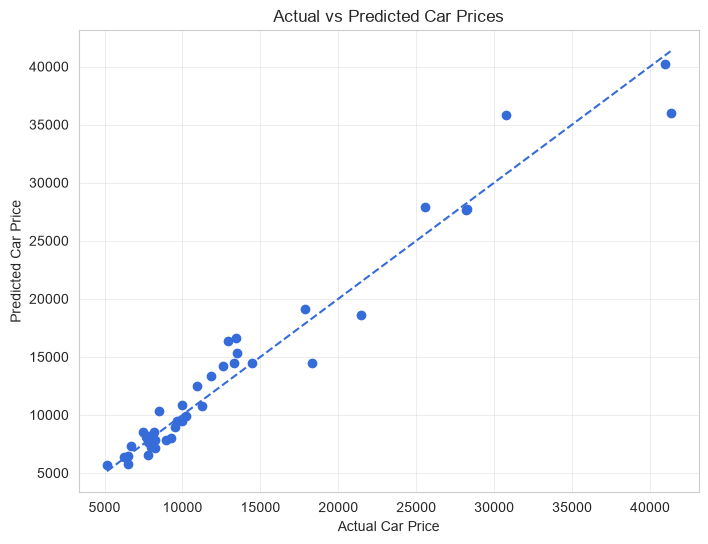

In [45]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    tuned_predictions
)

plt.xlabel("Actual Car Price")

plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Prices")

# Reference line

minimum = min(
    y_test.min(),
    tuned_predictions.min()
)

maximum = max(
    y_test.max(),
    tuned_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.show()

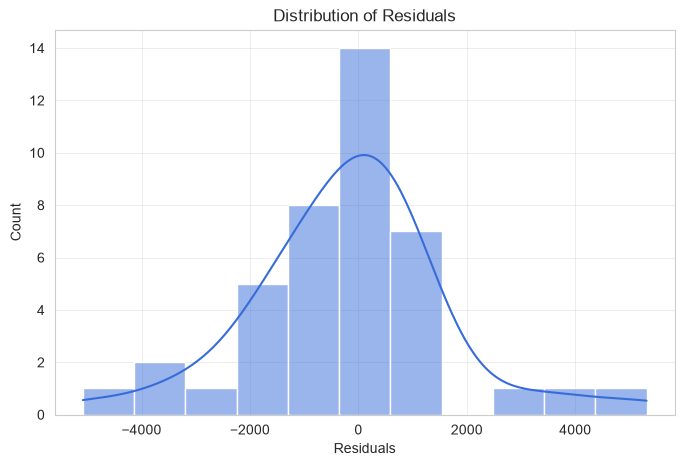

In [46]:
residuals = y_test - tuned_predictions

plt.figure(figsize=(8,5))

sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribution of Residuals")

plt.xlabel("Residuals")

plt.show()

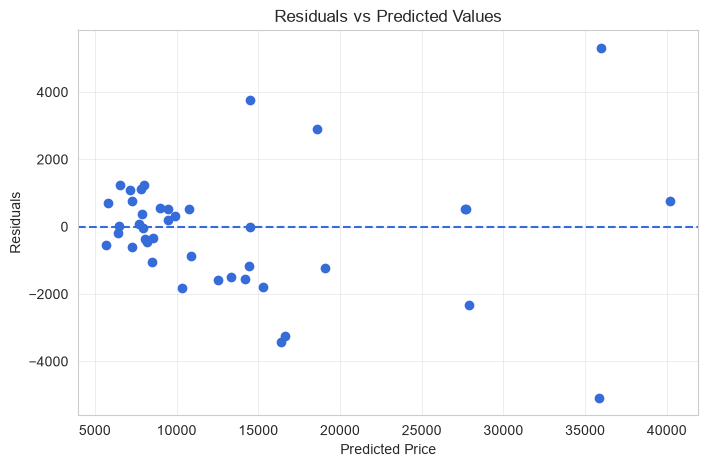

In [47]:
plt.figure(figsize=(8,5))

plt.scatter(
    tuned_predictions,
    residuals
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted Price")

plt.ylabel("Residuals")

plt.title("Residuals vs Predicted Values")

plt.show()

## 12. Conclusion

The objective of this project was to develop machine learning
regression models to predict automobile prices in the American
market.

The dataset was explored and preprocessed by handling
categorical variables, extracting manufacturer information,
and applying appropriate feature scaling and encoding techniques.

Five regression algorithms were implemented:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. Support Vector Regressor

The models were evaluated using R-squared, Mean Squared Error,
and Mean Absolute Error.

Feature importance analysis was conducted using Permutation
Importance to identify the major variables influencing
automobile prices.

Hyperparameter tuning was performed using GridSearchCV
with five-fold cross-validation to optimize the selected model.

The final model was evaluated on unseen testing data to
assess its predictive performance.

Overall, this project demonstrates how machine learning
techniques can help automobile companies understand pricing
patterns and identify important factors affecting vehicle prices.

The developed model can support management in making
data-driven pricing and business decisions.